In [2]:
import os, sys, json, hashlib, warnings, base64, zlib, io, platform
from pathlib import Path
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, average_precision_score,
                             brier_score_loss, precision_recall_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import sklearn, scipy, xgboost, lightgbm
from IPython.display import display
SEED = 42
np.random.seed(SEED)
OUT = Path('results'); OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
# 한글 폰트가 없으면 그래프는 영문 레이블로도 정확하게 읽을 수 있다.
for fp in [Path('NanumGothic.ttf'), Path('/usr/local/share/fonts/NanumGothic.ttf'), Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')]:
    if fp.exists():
        fm.fontManager.addfont(str(fp)); plt.rcParams['font.family'] = fm.FontProperties(fname=str(fp)).get_name(); break
plt.rcParams.update({'axes.unicode_minus':False, 'figure.dpi':110, 'font.size':10})
sns.set_style('whitegrid')
COLORS = ['#3986A6','#CF6558']
def savefig(number):
    plt.tight_layout(); plt.savefig(FIG / f'fig{number:02d}.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close('all')
versions = {k:v for k,v in [('Python',platform.python_version()),('numpy',np.__version__),('pandas',pd.__version__),('sklearn',sklearn.__version__),('scipy',scipy.__version__),('xgboost',xgboost.__version__),('lightgbm',lightgbm.__version__)]}
print(versions)


{'Python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'sklearn': '1.8.0', 'scipy': '1.17.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}


## 2 데이터셋 소개
Kaggle: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction  
확보 경로: https://raw.githubusercontent.com/benbobyabraham/heart_failure_prediction_dataset_kaggle/main/heart.csv  
Kaggle 다운로드 연결의 제한으로 공개 CSV 미러를 사용했다. Kaggle 원본과 바이트 단위 동일성은 별도 확인하지 못했으며, 표본 수·열 구조·레이블 분포를 검사했다. CSV SHA256도 기록한다. 원자료 계열은 UCI Heart Disease와 Statlog Heart이며, 통합 자료에서는 수집 기관 및 환자 ID가 제공되지 않는다.

Age 연령, Sex 성별, ChestPainType 흉통 유형, RestingBP 안정시 혈압, Cholesterol 혈청 콜레스테롤, FastingBS 공복혈당 120 mg/dL 초과 여부, RestingECG 안정시 심전도, MaxHR 최대 심박수, ExerciseAngina 운동 유발 협심증, Oldpeak 운동 관련 ST 변화, ST_Slope 최대 운동시 ST 분절 기울기, HeartDisease 심장질환 표지이다. Cholesterol 단위는 원자료 계열의 mg/dL로 표기한다.

In [3]:
DATA_B64 = 'eJx9XUvPJUVy3fNbbn/Kd2Yt8cy0WZg2GvBIvbJadgsjY0CAZPzvXfmKOCeqit30R07ezIzXiWd9+f3n17ef/3j95b8+//b7N59++Om7//vl8+vv5z9++On7f/rm/PvPP57/+Pzrzz++3n+af/12//e//eWfX19/+uOrv7/+9sfnX//jh98+f/nT9z/89On1rz/+5y+fP/3369vv/v3bH38+N/zq86dff//rueDTb5+/SO719evL7758+fN/hXa83OvDz7/+z6cfX76G14fzn//2y8t9kY7X+9eHL795+eJevjlYlsu5zL/e//jp95f/Ita9X+z7xXPht9+9jgZbtXOrL7/9eK5or+ATbOXa6/zzW96b5XRuNn41n796ZFga4HDx2MuCe8VId3Dww7n/8D7aedD7ZeNHxzJ/LjuPpMsS/ui4aL9GfziHu53b0zXmjfuOob8J3jg42nG9cT+f9w8/nJu8cDnJkdYLH+dvBqHCsdf0X3T4i+crIFXhDpGWjTvIDcI+ms/raOdv+vPE+GxwyRqRQ/ol5T3Oi7b9s76TtcDSUsaO+2cj7unwRQpco7i9nzuXJaRYyMScBZ+lIM1KP2OkH+7r+oYhPlAiJdjOE13HMr8vPKRnLkz2Huluv9z5pPETfoTjuc3wg1NQLiJI2riuLHMkF7Asx/18/XTFLeL6oD95Lgr4dHRXz3utm/r4SoVIgcziZbd8vlx74M9xsnGB86/Z47LokFEy3tQTYX2yoj1uerJxIEHsBBP5SX4v7PudinDxu6NFcteunRqycYYfjQHuGjL+aEYmziCL0Z2ivZe1atSJlzc+SZE3vYgzUeP4Ws/NxpJbNdyZLVz1l1A+wTVDdFciqPwLsx1LLXUB+qh0ihk5vOBbFOSiIHTvNzzWXqTMlWn7Dck0kOrKB7BGJB4KdE9V6MEKPZ2NDKZHquP5VPZOOYoJX60l0g0elKExwMzjDngyRDxf8Kj8U92UHVoTnuZotC7jTU5p8CwN+6U9ms2EL50d0ey9igwhhET2cEj/2rGDiSM9PaFHglTCHNEAhUYKMW6R4AcU6T/PHUveQj3JoYw3idGptuT+tFBoC8W2duOQkQ41EYO+F+zCYl/RBKPYs0pKuFuht0BpPbUKsrtD5eDCg2YdWEMt4ZNQT8g0iBpOoa4Pp1MV1380ZMvszr5u6ZxU5uu2bmeSvC4SKfnwwBu5Iu8KLRO9hdrTq5nMd8caZjxcGVz3A8EaqmQYStyLyMn2z4DbJBqim4+CfOSLfdvBku2Vw3GllOrW9/LTbAONnOrLdRYm7PDxCg0HdrhRc5vhsig6y5nlFlX3t4uEbYBFSgTysxJez7x/Vq5RLhgS6VFwv1Mx+Ae5KQUI59GHOPUTrhMC105g3HAAJtGuioQudiLBwmXJ9sMcG1rnfHlk1RLIBH4YWFWuijUv7gvSIyJ9I7kv6aLV9+k8aXUGEyrZEc93BOb6KI6k38LWr9vwNxuyHgnGsCQIwDYrB+uCNXNV8V1TBZIRh6KKbfnhQRIi11CQEqgRlU36HerWT551NaNM3MvhTzpAavFA/WQAqYMbpAIQ0udAirGATmHkGhLxHatZBzvSozRUjHljP4/8Rr6N30uuyGqLIGu6bDm373R0K4LOlAO9mQ+ALexiBAJguaKKyNnwbgRYBTJYi1Ul+3gNn+x4UsMaUIk7fDDACF407ld121ySO6hubQO6h3ZjMxULK0aL5//Nb7eGZTQv77fbQ/EHWzbU3DYk48kaW0wNaeThmfunk0mAoYtVJR4/7mBQV25JXB/WHovurUsLWRB2DDSOYv0aspdkuIgKhr+B3Qpy5XErKadmZqM/UGG4C6bER7kTP2m4LGRUA2PuKAj5xEjhqkRuH9gFy3PscW87GNvGQoFtIFnfuMkVEvNb8cCW6jqye5ZEi/cQVMn25R6CRn6r3nqrQsJWIYONClEAlFEhsjd8iESIJV386MCIZdvICBwyEEYAbwYVYZTjDS0Dy1QhFUIODbWWBne6OkoUlmOchNG7wwqDB/sNDEJhvhgMZ0oA4mgPP8u0SuLoF2sVRBs94Rml1/nqxT0DPaX9xSkILKjq5fn8J7YZdquPznFGDU2u7AO4QIreo5Rzz+6hehbQeDUKI8hq1NvFn92cTsCHNAM+cKD9HPO5KMyyg/YSO/Nim9FL6pGHf/nHV+dJD5IsWRV6ogB00XDIHcvB+kHGi+SQM0uWJ1IFxO3hEQcWtYDdXnmrx+9kOURRNf3JMEEAmIGcIwquKjDu4cvwwJMaDEkWViInBVaC8WGZxprH2ci3vwSR1xViQPYonEeCszXKwQQiAjII0iqmqwuwFxLKi/nKlXshuWMuY3piRQw1JfaE4Ea8UGLOFMXKzChg3JC2h7u7cLRcF1i6PCqc8PSr9ICJEkCBH5AMfmzInzch4G66/BN4UMYrM4E14OURCOgR6sqIkxBOJYr9RfTZRpTCxLvWwkgQyPMdhFNap+pWS8Hm6gotc7rsxiLVnVYZ3k65sx6XmCnJlsROTmb1BMrMY2wrmU2eCf3mEhZsH3r3KZ4EWtX6J5GTVqIvsw1lxWIFf+/H+JjUdK7reCPggHLQ6GfrUqx+I4IHqQLk+wjeFSAv1x+UOcbY5IG7p+U3RUmgClCUaeAuvCHxJmM91EnMoHvnYwwDiOTUNSPNcxOhWQ8bkNk6EfdmiO8o88XRKPbYxMaczrSJb7HH5rbHdtG86eopiKdbKdgwRVkRqIbwNw0oP0qeeijEQuzBusVrdWf6bf6IcWy7YaBLDcJwJ0heMKOJyZRndBHItjBWuXXDhpYnxcDqVFynrpmdybojymviYF9KKTjmALcl3N4uYe6NHTLGQuhRFPxkk+4zj4w/y6dD0CWY9lSVnklhXCiDpPPDO8cKxtnXnTfCpIWmBUf+kBA+RkApJd8oxV/pBuhnERkO0viah5opXggec85VQJdYonThcymhIFzG/jVa3BgvDq96lBmQL71sLPeapLMmxdWoVoXWsd1y4fLD87an6xNIxO5UXb8tu56JoxOy3/CfEcOnaEAmJsvM09wHwdlgukiYZUfPRuoaWWUID0Yg1MQZGPrRFBht2oXBVX7br36Lv/78vz9JunfrFFGw8cEZjDv0QDjU5NaWL5IOukS+Z4NLptGTp1SUAXeESkLminBAe9LL5QDuZUa1g/VAw3HkFI28cEX1RLAW68biAPrDvpIzwMk8vCX5NR6TwiSNE2GeNDW/eVKU3SmKnxR6EMKZ8G4cTgxErKbvxknm6JlUaNKRSzxJYmDii4+UrGxzqpaCBtHdRPdu3KTjCe17TTecawI/n7tRFROmY4TBE7NTZR75wAl4GLP54c+CB1FiDC4bFVUek8lUNhbdRTNqHNhtDo0InjLExVlvU/JNHPS2Kyluca5Hz6VcHvgm6lltQjcUU8QhxrhH7tNGbWOZe2tXZzTu+gtImE494fA9hk8y3+O29jFbiMW1YCqz0RleKlPBGon1/fSS4LLeiMR1M5K9ujslcYncBUspjVAfD7ymgZlR3UBMdFsxdkLA6ZGMV4WQOFVPckgcOShJFMA7U8aKWdlUMc5G7k3MoMsjqhrKbWECWvOtA6GpHEcqPwvT8A7uhwDxAGhvtW+FdsjxMr+t7lhG2BaXxRHEPHejHOryNNxOuQ398pbWXt4s2acPF2VqN0odNYY3v84uhyq00Vzm3tINlnKvHeSYqvEt2JcP5rncipfNnwwQgNmnCrM+q27sIRe0Lz/Y641lDTcDEuHbM7UhBD4E/M2TX7F1Bcdy9uEwrGp2m+wqP1rv79ACbocVIplYcda5eNBQd487nexNz+Qflo0MiX8rc1lMT++RlKKQC2qODpa84kT3RRVTvBh7EbT/XoSnGCJuRGSK5JsaJqyqIXpO/m9W5CItqwMOQ6KwPcncfI61ndow+2rDWJ+vtvcTFnd8PNfF5Z17OyCb8v5WKZTJwU2E4Z4QI9LRb7LBeDG/PJRCf+R3cD41GO5mu3ce9sMqLKTt4OF3i6HQaFi+m1rrWC8Ybnl9lOqJKUZ1E+EWU016kQcxxuZNUhxPt3VgMU83SwPPwy9Z0Ay24yvWQSy/ryhVMIeyr5bmmKob4g43n6oCLZe1cztDNRDVO3iCihFGAV6j6NxvQpqytn2oIZxRfi4aURkbTfW+VuzyQ6OA0sxfyIOnJ64euAaYpqja4IV+JuijLHywT73I/8MwYxe0Z942cLgHYw0kd1R9VNTNYE1qiv8P2s34lzeO6FU273+0islw80FEMGN5eBBTjBsf7snPkZj0kIFR41PMHaW2/p3QnermaI1ns8/bTJCxVXvZ4feUlZ2NU8eS6pAbGNAj9ERQRtupXJvtAtVZaIjQ5T+hcrHyuE1JuKaMBSfBb6b70PUy5bPR6oNZYemS2mXJdkbwFaqucircwWg3bsRSScyG1ytGNkozkiOpLmfAzGY5ivKEq4Hkn2sURwEzQKQpEVm4lIeju3b/k42RfIPTPykGrq8sjJ7gF2c0Y8lNlTBQAZDo1WJoFMMgOk+pSAV+BZDw1LlyveperOYFqhEBs7vhq1z0CQzS1x5Ad1dHZCXL8UJVQGZhohy6giADMjIFfiHXZJaxpD6xsqNYEzjNzA/HRTug7tv+/q3yY55v8f5YQMVEbYRqvnijQlq92tefuvbj3U/hof1VOyJyMDS8cTPZ9eOen8iKgYqHWIu+f4l3aCCbyeWv2M5+KqYeFL0Zoxt26m+9Q5evoGC4sol3kOa6uktXwgAeLUzeTOw0lpTt/19RzB2KvwY3LQi46Xm7AQELKIcrBc2rcw/dk48xLNw7Z+tYbqIKXOItdrUA7gzh/icVvo4O0pvymuaufIWYQA0mv61JkajRzIabu4t0/dl44QuIjxapwcm8GzM91RLd9sF6UwYnKTdsbgVzGKBNSLrgNlxTTgyreHcFdKanqEZTg2lx0WcoP/8m3bnFYgyJc7yTlALEJXoQu9zKqzprzUBRqCWm8CqpB7/jodtASVXebkHNdcVUiB8GRiwrqHip6D5erG4HVSqZ3kCs/mzpinD7aKDc+JZBsjaCNrUA7f73JODe3VUoKVFmOjWZx7aotlPVl1CAn3ShZMotMhoZFyCycBUyXw76WNDYBdGuwk8l4Sn0DCGo5wql6/QlgSoemalKBnPUlQFuKhRo1Cr2JjuNiPL2SY7XVa2PdPmNSQaaTWfs7Q6nutH24tnTusP03ibp2MPRAq4CMhyMu2jUFHKw+s5V2S6ttPBqolGZEg4oti3AXaFOP9cNAMPj68sHJhBljpUbRloDKv399WnTLn8QxsNKfwtrxRZGyKQoRjkflUu5ozGZmsTRk63Y+lZ7/nXrfjUyqukpHlseMOsYluFF6r0tPRnhl4SCofpMK0qO0THp8a2Oq7hHEtTGLqoGP4LpCl8MFi9B+C1nwjvVKNvJ0Z7VQ6NiAuGc8yECtbdTtXp+3dgl08dQpLwiMhdGiIU7BCFhdIBPRF2XqEGYZA/aoJb24jFRm60ulbcgVwb86GaPdttkkYUtjNVE03pySPRb+0w5UvCpNQ6GAPwaSvfaALZx5Z1y6wQiO4h50Ls+BfccUTxzHZRHu8gNP+OOFTyaIbXY3yIFi+PxvVU7GInbxQNOpeQDWk+NV4XRWEGhuA8KpHIzmmeczO0U9CV3ExMrxLCC2iScg0rHqApcxGxGP1ENp09r2UyXzsi3Y9yvrZGJ6rQLVl1lqsDOGr+jkoZistWJeFYD18HZMUyk2it1PA91PNAABblGNt3k2YbTHIkZp8aoZkjTSu7VG2MSTLHq5BAQKmnJH/Qv9rqm22/JQsrQiVgmkNj4SX37YrpL0yyDQ8bbtji2Tdr44Kv1jo3jacgKMV4xI4zGPZL8LAY6qIx6Fsaz9AhXOfJCwr2GCJuNV+IzXBRvGz3gpuU9kkcjaCjtMrRlj8OVoQaLZitmN2OOei1yuhrvebxKkn3jel7i46OuwhQPodZ3cEBTK1tQ2BiPbR+nccRFTWBcjaHDD4qUl5Nk06j3lOoLh24exukMXsPisQs091qIog6jBN3XZDUIS1DRgfEar3N2TBXiJFdQfT3Z3HLvUVaV14q1aiyI/Ouwq3vCTsXv81N/iIwRGAE/kRUo0UivOHoJ0N0zoeSOFrg8kVzMjA+hXdHUbZDh3dmTmwlIoXbGg3mp2PfRKEJt9jnWML17rZ8QtflExUxmelTVeGo05TnuYI8EJg7FFcggNIj2MMGuc3qVzjvQbCkUbhTwwByzXAQ5nbbuRnNhIpvLt+LGl5sNsJheQQn7L4pno/LuYRQXzqYJmdrnlek4QBSstrwJ9w11VAWTAEfBsdqa4weYUQ8msOtc4kfR3mb0nmHOcDYYvUgFr9N/BDYR2ndQJdW44SAb6LGG68D2/gAaOqHtDTpN7UAro9pjmCJRW8waHtCek8CEUfSaaeralHrxE9cutY1ajlEa52EGw1sAF2Y+ROD65RopHsK9+JvPMCZUBQKlZMpw1+TLRqy20rDBY3+FL0akRNmfJ/VS+z29MEGFqO619ps72Svmr+LVzkuFEHT01AEtyJNpBLlkWRQWSqxlQOMn01HuwkWytowGt03DbDh5o7795UzqfJnk752nZAu/M6BuJH7Hb26DvFW5ehMx7IStYHIRkCmy9La+HXR+wrQYdwfwBKnFT2orPe54k0C6zJcTmb9EpAfQoymKBndDjKyBmfYHxY2oQpUYapmafGWCgUeEtplDc2q8eq9I2OHw1VwO2+kvhwVZJZR/m4zoHNpQVy8Ss3jvoM30biWnrnkG5YMT31BJ7ioePa4s07unqqhszwpW75EH8RBUgaQpI/gZHpFnARunalg8AuH6TQ4Tbw1haZ+hyijwBN55WL0Y0+YwQk7I9GkLkL+Wfn+txeltK7EFa1nXbbDGLes8eER7s08VNz2HcbgCeVz0HBJqRd5Kg9jJdCJzHg0iAmVlO6WmT7WTdlfu6vpFTzX5Qstjdp976Ta5DcnGDUVUEG4StGW36QHOtIUEEhSflWc2Kl6RKYp0wTj+RYXAcVVwjFco9yY17D7OyTo7DnAH3CgQPFuG7w6H05RwbiMGgkeImlriI/tZFDOO2Hp1sMVUrZWHxbwEjBSTqDFMY0QW+KkesjNSAO0T0PUoUDpMUxTzFin3NPbl9DAEKdkZhOTaq1aLPOFGyZDMLYMt/NjV2z3EsyNFmeVke7q9cSRKF1p9YJAwrAvgvBvm7t0UQ2dAk4coIJpbnDfbcl9ARRmIQfwxd6wKVdXvOgY7qwwUx+Weqs7GRGUCoJ6q7TTP1kw78MzLvgkUqdTDVdSZ9Wud8SyDSTuulKoEHakrW1VDmiW+mrqiPukoP5uMC8IJoEPsWXVc/1RkqFmf7+nE6xlMkq6/2nEXDSYvniMBwOkBlYkHqUqsw/Prpt1eXIsunzwK3VSNa5/SSbTZcz2vcBDU33IcRk6fkrrELAlr5KO/tlze2b+0FeL85c4rEUqut/cgHTiTZgm3W5XS0rJuxoN/3O0pJsI2p09O1pulClqufp16Ac+srEzlZty03jyyC7b8d1fOEVkiQfoESaQ+jsALUdAPhU4u6pY0vmhBPzkphaEqBvu0pMd8rpq6rFjXq98gMhQBRF2x66vPN2OLrpmCnSkHQuQt2lvICpqIIOMl4kyeLNWo3xuQQWlC/9vyi+pW27UChPh2H22blVwbEM7OggsMZc2ToTy1eGL0CheYKFpjd7vCRCG0zjOgPKWz363AyB01UKsBQO89YWUFdzI2KBaFfqhkhu6vSjSjki7TvOss40zYlDt6Rf0IEwFwKIZKk5hl5fqEt9OLm6xwPtQc06MceZnT1LeC0GlZiHy+LjYQQAirVngPOb8Mfb6vkysZLMNMC0AvhXCP+mHFjGMINtiopr+NOejQs8WjWnWQSfIKuKte1UGSOjmTE6g4uIG/MSIIYTYxg9LXiTOXDuBmjNJWRLM6arN4l70C1heme1Sg/nEZiTokOZnZOonwEIOmJgbE2XYPLYx2s4BLH4X9HpzwyO3dFkioYIhzIC8DD132hJcxdRHluk6AcECKZgfSYgRlMzXhDmnRaJmqKMLCIVJMxYOiwAqr9+IJRn/IbwbQS/K1hOGgUlvr8YIeOgdlpq7ZCY6wI2dEKJGxNPUdgOl9yISu4rrvRDFSw5cLGvQEiqwWEJ+pA5aH/0FDZG5C5+n5lttPqkgqA8si50yT+ZuVfBJZ5dKKZcxV4AU5HTZ9uuoG4KDMBrSDpLEr1A7jDKhg8zvzeypbWYBrUkzixNHMC6oNZjWwqoMLaW3lUDGvE+eKRvZoVrx6KFCt6zj1wIMFuCl/9awP+WkjfrP1Gd23sKZtEENgAzVGMjU8/gDX6U1iyzDrrIxE0r355DlbitBCM1id5i1RyL0kyCGTfgKQdqiAQVtDWlNgtpP4kcxrosfVddzOpBWkmYdbTlrtBmCiVFWjyOWoWLEYncCX7BEX2vATOTkTS7xpFlaFOtIUCBPQcuiVJlIlYWmAjXfeixbzVFdhbSO7Gxh9GaodZ9XAZMXyhLSgMWLHUCerEK6gugqNE3S1QyYPkGJaqYPJKQXdUix3cXa8RKIixmXKMK2IfsSFl3c4nb+0EBQ7KwTprid/2qOROhPA1edtBNHcdeF6Skhsb5IqADI8M9yiLRM/H8aTCOk48OgwCIYeB01q5VElZpbotrPJTAPCrKGda6NgdiXld9f4dvq67wIe5ChNTZBbVNxB6MSnRS7MkglHNYEes9Fhr/MAtceADrIBx+u2x6I7KU0xShkEu0ksd0cFs1vNlKcp9O0Zv+KM3tjWTBFZRj9rog8tPVfqFmtVUB65dh6/U7K6GhDAb3Ypa6YeaGXFFgr0o/28WmY7pS1Z1dRPz2Fouxldo1Qdc7FqMYfkZLPWcsSJHLcep4G24QodbLqEBtfMsVVv4ZoJHUU58ptlh5Y0irEzNFNf7GjlvOoueZM4wOCXx5m82LnTpciLFBFT6SR838wnQ449KsPWQdvPdxRoWIAUUjYP/OGuHmSUNigwxxvwKON4YVCD89fE1eAxtABxMc01H2GV54xVBwQgIGUV+dsMB88nxi9P8UBTLajGOvXucRehqadi0cy1FIra4qgHCYIVtw8S1ry6uSro4yuevAwiRAid0f+cmTSSQIyNIxAIegOckqhVndFOtcTZTM7MZsoamzpeUg+3w3nL2eYgIjE4jdvi9HcH2Rl0ts6/bDi/leJme0J42Bntec8Jiw6x/hJr7MA4YOCm8OD6pvvxcLYxliOCSgoIKAiUZVN8oQXKA0PR9x5wEpminrY+yKcJ5pvyxMvkJ0UBSN2BO7I9HvKU7KaIDMPsGSsdZ3BMTZMHr0K/Y9aW5wYBXYBiu8q6L2uSR6+JQWDBwGNMghQ82yUqYEdMyY1UogY77jg01JY5bloayZhoOE9NPfBtlvFtH1GXOApfGaTf80Ac5gqypw14kIc68uQJIjeFrBJlvepQPOV65/VNTG81MXfCz2sf9kNfGE+l8quEpv3YME+B2b59eiWHUfSPeHX6MuP8COhc10Afy0u6sL5KsqsLyachRu2G3YNG3lfANRzaFKVhLPGocdJU/Cx89Feb0lVtxEaqVDF5ovyQeMJl5WxMFVoU63HNCjHgG5q3T+X+ZacEIca0zLunWqzVKFS4tHLo8bZCQ3ehcAiqlGVy521gfIJWG3Y3LmNsmOZNajg3L/OnTo0nxxo/1dSIDfzV9HnbcmGtZDm0AZ9fL8+fXoi2oiBFp+4oOIRaetABGeG7udlFx+dRMrAVByY3HMmtht1G4+9dQVLaOg1Cah+hYQtrDmd12g4L0aSpvMNQHaJSoWltzKMaCj8lkr/3Sp1pWqyesUJoWiAgBDo/zHPRsydAH4RgrNSm/lNXSYJhbs1OB9NG4/DA80qSE1xDx4T99Fujo2CLgG3GLa0l9zoa03MUSweVj4qazVjBPX4ZVpmvhiUdmjnZTv8s59ZVdpzokcy3iAkRUGoAuK9ymIu+y809UATQKFDHHUmF+blQHaha8jBDNMqmlBChEdB1jwTTtAQGHDeE2DW0QzoiwhZP9f+N3lhjNKNO9earTJudAwJmLDg5SNfvodfLyPRJ0PuEheqMGoRDNMZRcBqztLbsbw1OJ8nRuSQA22d7a8I30ad3YWh/M25GMnUmmiAYnwsT+aYp9gFlIZPB9aA/MYdscM2eO4jPu9WZ1wKhEeUu4MBHwqNcSIRwgEt5Js+ZUlzND/W9slbUFHvT/b0JgtxTDKV+SNRim5XRnrBRIUpIgDjcu9vxhfFZfYzI4kroA/zQ2bEE5l+cvUQfzUh7rJ2J8ch4YKHWdn4mWTOKv9rsFTIqsmoHRy7f+7zGliQP1rQahLogC6IdwCZzMj0oEgwEcVDQztwzXzkWE4pfZ4JEfVgf75qHE/iJxmbAXcqsR30SLDUYzQT0CbKKSq7id74jfUxwBmjFRHjcMSFQjdCERfX4p1LKRs9xbBNrviKHrRHAP3++b2YbZCI7ul/8QXe0ZMx+mv2Jk8AJFCem2G0poTBCIjtMQ5dXontH+2RDv4u0TEJpi5Gos/7ZsuNA32tHdIFppOKQSlQwvyLRlYH1EvEWzKihNmf+2NGSJNUI9GXDxik0HjC4aUJgxlslL+qREs9YT6B80ENmSSIJszDizqcKbXWEgA8Ctkog3ohJXxJjknaQWr0OBUMltYE4VIO5p1NTVVuRedevK8fL3HtaqBWqOVEEGQelNtDfnpuXPZ+OEsosbOMB442xstqZ4okCfFbpDnyrwiTP1zcSmKEo2KG+SDPYiHJT2ieTlt8gg4gSVLnJo9RZpeQBqATT/CTfieY+/MTcTp+WCmpLCwsZyCLP25jvpsH8rUopHbFKBLETU+slIxWglIL+eSJLZD94Pe986U2Xj/tphuCSWen9tsxU/FVH/IKPp/nwBDIEEvbPSNYdWBnoEvuzAGHwV00iRgAXbtxalL5YFM0kRxhGnUaAl+ZgfcAUKrUn+OuHNXgIHBaQiUqrVESvM1O7Y0C2GlXz/wOEMTcW'
data_path = Path('heart.csv')
if not data_path.exists():
    data_path.write_bytes(zlib.decompress(base64.b64decode(DATA_B64)))
raw_bytes = data_path.read_bytes()
df = pd.read_csv(io.BytesIO(raw_bytes))
required = ['Age','Sex','ChestPainType','RestingBP','Cholesterol','FastingBS','RestingECG','MaxHR','ExerciseAngina','Oldpeak','ST_Slope','HeartDisease']
assert list(df.columns) == required, '열 이름과 순서를 확인하세요.'
assert set(df.HeartDisease.unique()) == {0,1}
sha = hashlib.sha256(raw_bytes).hexdigest()
print('데이터 크기:', df.shape, '\nSHA256:', sha)
display(df.head()); display(df.describe(include='all').T)
print('명시적 결측:', int(df.isna().sum().sum()), '중복 행:', int(df.duplicated().sum()))
# 동일한 기록이 훈련/테스트에 함께 들어가는 것을 방지한다.
df = df.drop_duplicates().reset_index(drop=True)
num = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']
cat = ['Sex','ChestPainType','FastingBS','RestingECG','ExerciseAngina','ST_Slope']
clean = df.copy()
for c in ['RestingBP','Cholesterol']:
    clean.loc[clean[c] == 0, c] = np.nan
# Oldpeak=0 및 FastingBS=0은 유효한 값이므로 보존한다.
X = clean.drop(columns='HeartDisease'); y = clean.HeartDisease
Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=SEED)
train = Xtr.assign(HeartDisease=ytr)
print('훈련/테스트:',len(Xtr),len(Xte)); display(pd.crosstab(pd.Series(np.where(df.index.isin(Xtr.index),'Train','Test'),name='Set'),df.HeartDisease))
clean[num].describe().T.to_csv(OUT/'descriptive.csv',encoding='utf-8-sig')


데이터 크기: (918, 12) 
SHA256: 948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b
명시적 결측: 0 중복 행: 0
훈련/테스트: 734 184


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,918.0,NaN,NaN,NaN,132.396514,18.514154,0.0,120.0,130.0,140.0,200.0
Cholesterol,918.0,NaN,NaN,NaN,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,918.0,NaN,NaN,NaN,136.809368,25.460334,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


HeartDisease,0,1
Set,,
Test,82,102
Train,328,406


## 3 탐색적 데이터 분석
그림 1과 2는 전체 파일의 구성 및 품질 점검이다. 그림 3~8과 통계 검정은 훈련 세트에서만 수행한다. 결측 대체 전 관측값을 사용하며, 각 검정의 유효 표본 수를 함께 출력한다. 전체 EDA를 보고 테스트 성능을 높이도록 변수를 재선택하지 않는다.

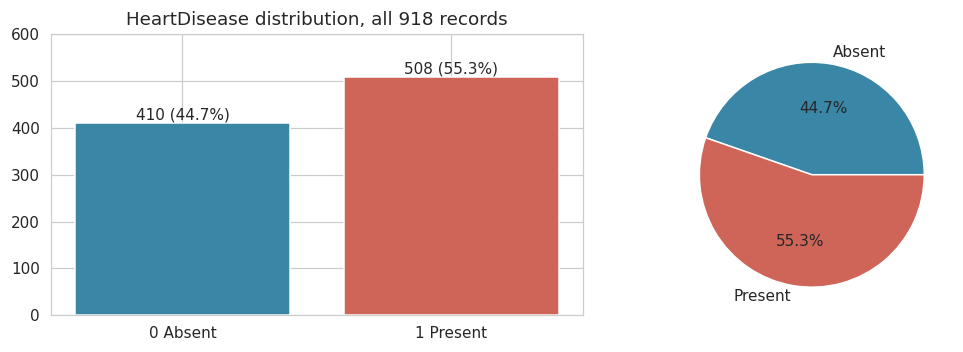

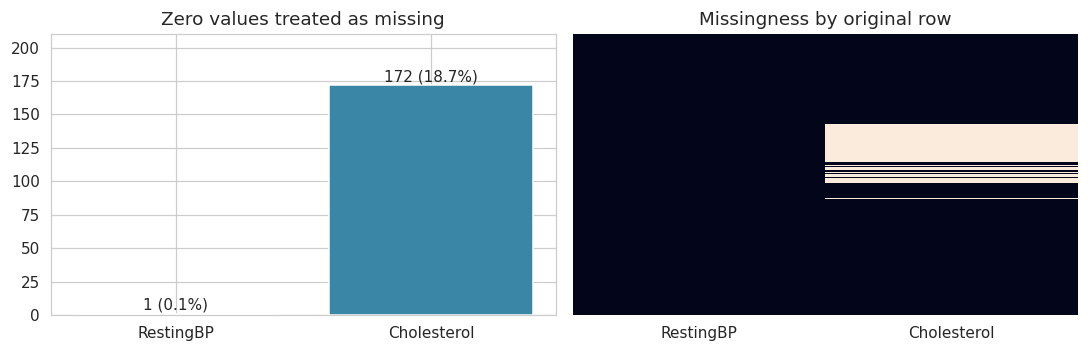

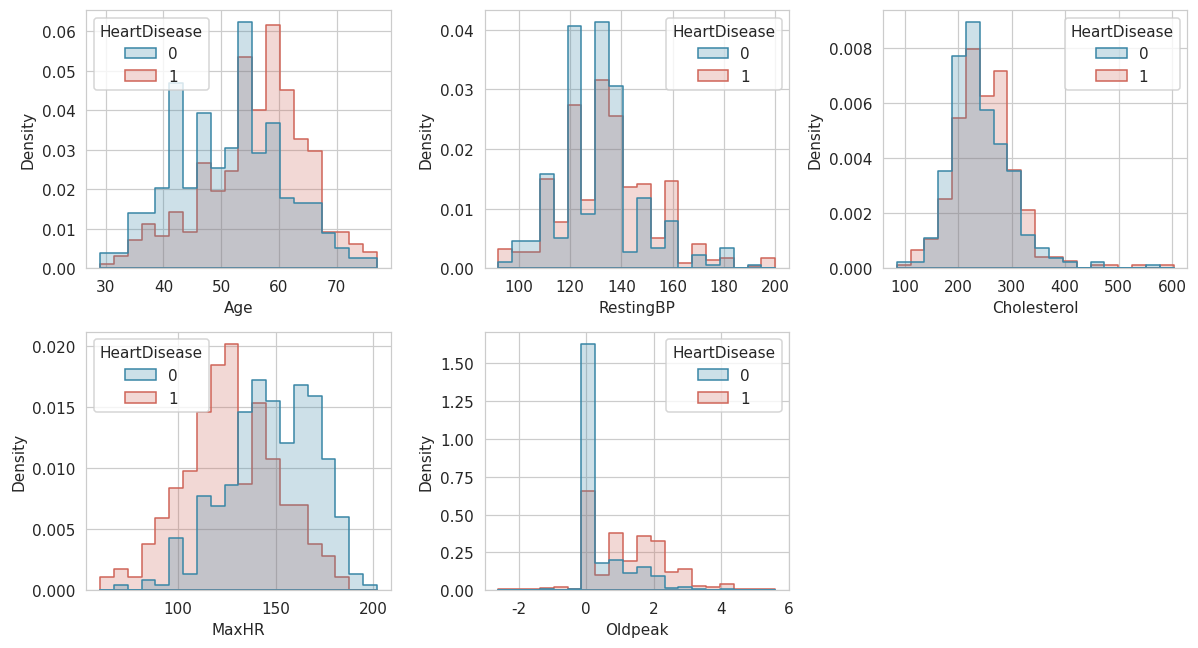

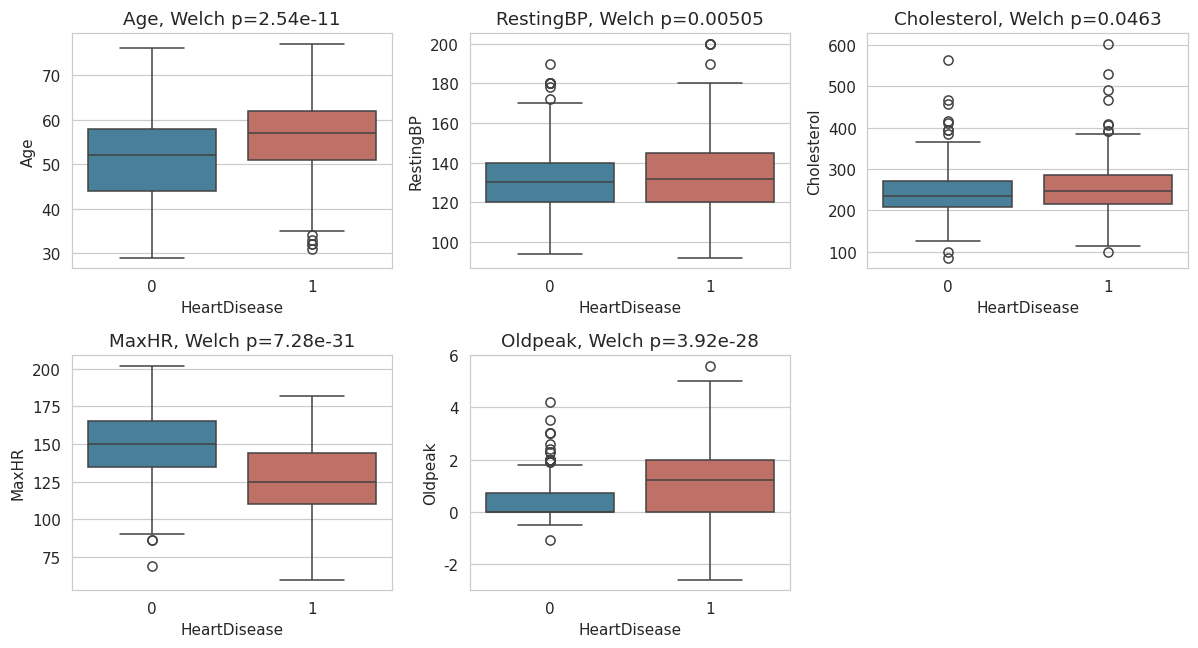

,variable,n0,n1,mean0,mean1,t,p,p_holm
0,Age,328,406,51.280488,55.923645,-6.784178,2.538239e-11,7.614718e-11
1,RestingBP,328,406,130.823171,134.532020,-2.812495,5.048587e-03,1.009717e-02
2,Cholesterol,315,290,241.911111,251.610345,-1.996467,4.634366e-02,4.634366e-02
3,MaxHR,328,406,148.073171,126.928571,12.119230,7.284186e-31,3.642093e-30
4,Oldpeak,328,406,0.422561,1.222660,-11.495352,3.923092e-28,1.569237e-27


In [4]:
# 그림 1 목표 분포 / 그림 2 결측 후보
fig, ax = plt.subplots(1,2,figsize=(10,3.3))
cnt = y.value_counts().sort_index()
ax[0].bar(['0 Absent','1 Present'],cnt,color=COLORS)
for i,v in enumerate(cnt): ax[0].text(i,v+7,f'{v} ({v/len(y):.1%})',ha='center')
ax[0].set_ylim(0,600);ax[0].set_title('HeartDisease distribution, all 918 records')
ax[1].pie(cnt,labels=['Absent','Present'],autopct='%1.1f%%',colors=COLORS);savefig(1)
fig,ax=plt.subplots(1,2,figsize=(10,3.3))
missing=clean.isna().sum().reindex(['RestingBP','Cholesterol'])
ax[0].bar(missing.index,missing.values,color='#3986A6')
for i,v in enumerate(missing): ax[0].text(i,v+3,f'{v} ({v/len(df):.1%})',ha='center')
ax[0].set_ylim(0,210);ax[0].set_title('Zero values treated as missing')
sns.heatmap(clean[['RestingBP','Cholesterol']].isna(),cbar=False,yticklabels=False,ax=ax[1]);ax[1].set_title('Missingness by original row');savefig(2)
# 그림 3 분포와 그림 4 박스플롯
fig,axs=plt.subplots(2,3,figsize=(11,6))
for c,ax in zip(num,axs.flat):
    sns.histplot(data=train,x=c,hue='HeartDisease',element='step',stat='density',common_norm=False,bins=20,palette=COLORS,ax=ax)
axs.flat[-1].axis('off');savefig(3)
rows=[]
fig,axs=plt.subplots(2,3,figsize=(11,6))
for c,ax in zip(num,axs.flat):
    a=train.loc[ytr==0,c].dropna();b=train.loc[ytr==1,c].dropna()
    t,p=stats.ttest_ind(a,b,equal_var=False)
    rows.append({'variable':c,'n0':len(a),'n1':len(b),'mean0':a.mean(),'mean1':b.mean(),'t':t,'p':p})
    sns.boxplot(data=train,x='HeartDisease',y=c,hue='HeartDisease',legend=False,palette=COLORS,ax=ax)
    ax.set_title(f'{c}, Welch p={p:.3g}')
axs.flat[-1].axis('off');savefig(4)
tests=pd.DataFrame(rows)
# Holm 보정은 다섯 연속형 검정에 대해 가족오류율을 통제한다.
order=np.argsort(tests.p.to_numpy()); adjusted=np.maximum.accumulate((5-np.arange(5))*tests.p.to_numpy()[order])
tests['p_holm']=0.0;tests.loc[order,'p_holm']=np.minimum(adjusted,1)
tests.to_csv(OUT/'welch_tests.csv',index=False);display(tests)


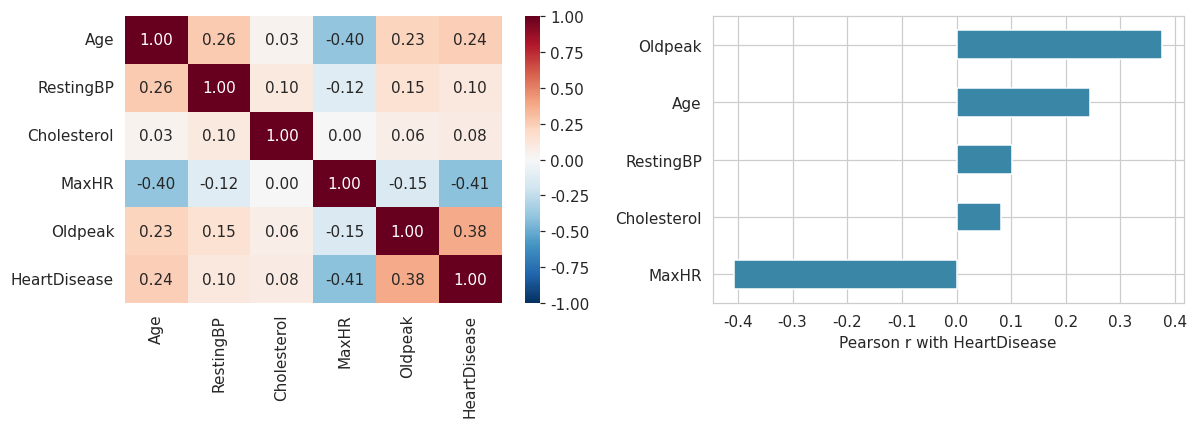

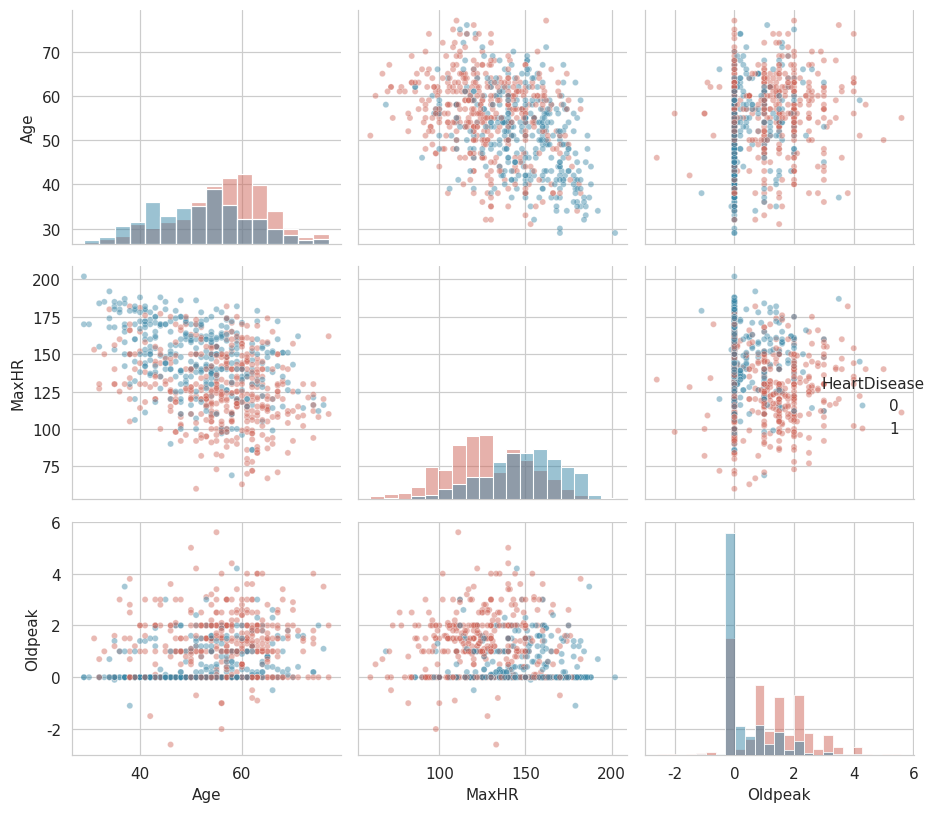

,variable,n_valid,outliers
0,Age,734,0
1,RestingBP,734,20
2,Cholesterol,605,20
3,MaxHR,734,2
4,Oldpeak,734,13


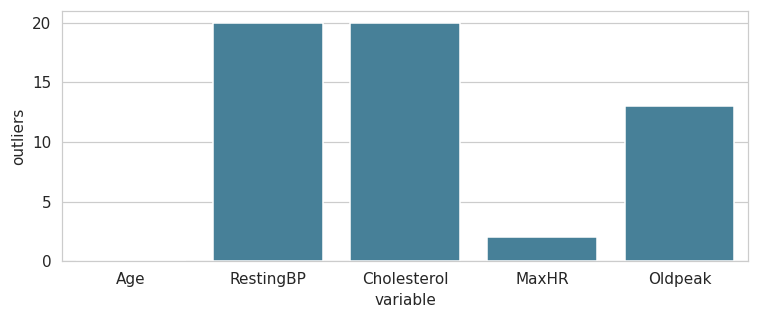

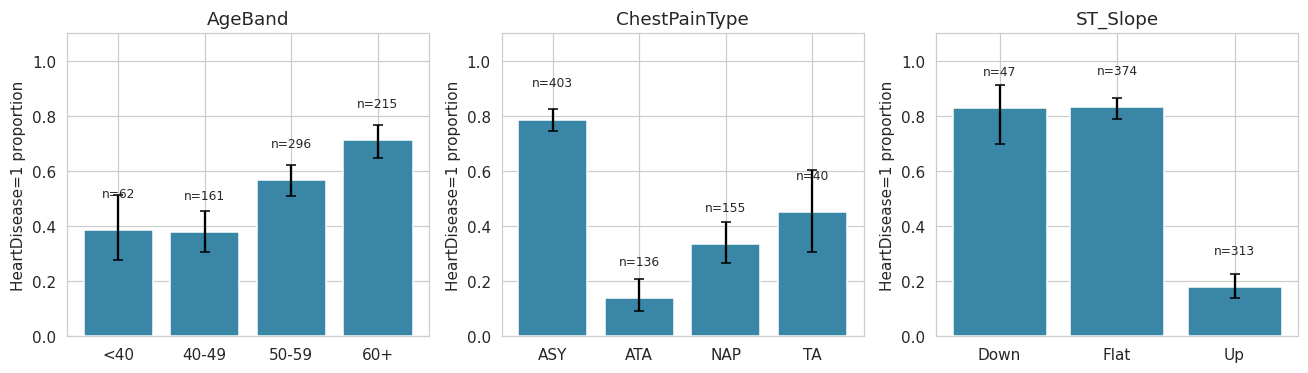

HeartDisease,0,1
Cholesterol,,
False,390,356
True,20,152


In [5]:
# 그림 5 피어슨 상관 및 그림 6 산점도 행렬
fig,axs=plt.subplots(1,2,figsize=(11,4))
corr=train[num+['HeartDisease']].corr()
sns.heatmap(corr,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1,ax=axs[0])
corr.HeartDisease.drop('HeartDisease').sort_values().plot.barh(ax=axs[1],color='#3986A6');axs[1].set_xlabel('Pearson r with HeartDisease');savefig(5)
corr.to_csv(OUT/'correlations.csv')
g=sns.pairplot(train[['Age','MaxHR','Oldpeak','HeartDisease']],hue='HeartDisease',diag_kind='hist',palette=COLORS,plot_kws={'alpha':.45,'s':16});savefig(6)
# 그림 7 IQR 이상값은 탐색 목적으로 집계하며 자동 삭제하지 않는다.
outliers=[]
for c in num:
    v=train[c].dropna(); q1,q3=v.quantile([.25,.75]);iqr=q3-q1
    outliers.append({'variable':c,'n_valid':len(v),'outliers':int(((v<q1-1.5*iqr)|(v>q3+1.5*iqr)).sum())})
outliers=pd.DataFrame(outliers);display(outliers);outliers.to_csv(OUT/'outliers.csv',index=False)
plt.figure(figsize=(7,3));sns.barplot(data=outliers,x='variable',y='outliers',color='#3986A6');savefig(7)
# 그림 8 연령대 및 범주별 양성 표지 비율과 Wilson 95% 신뢰구간
# 표지 비율은 모집단의 유병률이나 미래 발병률이 아니다.
def wilson(k,n):
    z=1.959963984540054;p=k/n; den=1+z*z/n
    mid=(p+z*z/(2*n))/den;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return mid-half,mid+half
train['AgeBand']=pd.cut(train.Age,[0,39,49,59,100],labels=['<40','40-49','50-59','60+'])
fig,axs=plt.subplots(1,3,figsize=(12,3.5)); groups={}
for c,ax in zip(['AgeBand','ChestPainType','ST_Slope'],axs):
    g=train.groupby(c,observed=True).HeartDisease.agg(['sum','count','mean']);groups[c]=g.reset_index().to_dict('records')
    lo,hi=wilson(g['sum'],g['count'])
    ax.bar(g.index.astype(str),g['mean'],color='#3986A6',yerr=[g['mean']-lo,hi-g['mean']],capsize=3)
    for i,(_,r) in enumerate(g.iterrows()): ax.text(i,min(.99,r['mean']+.12),f'n={int(r["count"])}',ha='center',fontsize=8)
    ax.set_ylim(0,1.1);ax.set_title(c);ax.set_ylabel('HeartDisease=1 proportion')
savefig(8)
# 결측 패턴과 결과의 관계도 기술한다.
missing_assoc=pd.crosstab(df.Cholesterol.eq(0),df.HeartDisease)
display(missing_assoc);missing_assoc.to_csv(OUT/'cholesterol_zero_by_target.csv')


## 4 전처리 및 방법론
연속형은 중앙값 대체 후 표준화하고 범주형은 최빈값 대체 후 원핫 인코딩한다. 대체값, 표준화 모수, 인코딩 사전은 매 교차검증 훈련 폴드에서만 학습한다. 연속형 결측 지표를 추가한다. 모든 모델에 동일한 입력 정보를 제공하며 임의의 이상값 절단이나 SMOTE를 사용하지 않는다.

기본 분석은 원래 11개 특징을 사용한다. 7개 모델의 하이퍼파라미터는 아래와 같이 고정하고 훈련 세트 5겹 층화 교차검증 평균 ROC-AUC가 가장 높은 모델을 선택한다. 테스트 성능은 모델 선택에 사용하지 않는다. 파생 변수의 효과는 로지스틱 회귀에서 별도 제거 실험으로 검증한다.

In [6]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
def preprocess(numeric=num, categorical=cat):
    return ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())]),numeric),
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),categorical)
    ])
models={
 'Logistic Regression':LogisticRegression(C=1,max_iter=2000,random_state=SEED),
 'Decision Tree':DecisionTreeClassifier(max_depth=5,min_samples_leaf=5,random_state=SEED),
 'Random Forest':RandomForestClassifier(n_estimators=250,min_samples_leaf=2,max_features='sqrt',n_jobs=1,random_state=SEED),
 'XGBoost':XGBClassifier(n_estimators=200,max_depth=3,learning_rate=.05,subsample=.9,colsample_bytree=.9,eval_metric='logloss',n_jobs=1,random_state=SEED),
 'LightGBM':LGBMClassifier(n_estimators=200,num_leaves=15,max_depth=-1,learning_rate=.05,min_child_samples=20,verbosity=-1,n_jobs=1,random_state=SEED),
 'Gradient Boosting':GradientBoostingClassifier(n_estimators=150,max_depth=2,learning_rate=.05,random_state=SEED),
 'MLP':MLPClassifier(hidden_layer_sizes=(64,32,16),alpha=.01,max_iter=1500,early_stopping=True,validation_fraction=.15,n_iter_no_change=25,random_state=SEED)
}
pipelines={name:Pipeline([('preprocess',preprocess()),('model',model)]) for name,model in models.items()}
cv_scores={};cv_rows=[]
for name,pipeline in pipelines.items():
    scores=cross_val_score(pipeline,Xtr,ytr,cv=cv,scoring='roc_auc',n_jobs=1)
    cv_scores[name]=scores;cv_rows.append({'Model':name,'CV_AUC_mean':scores.mean(),'CV_AUC_sd':scores.std(ddof=1)})
    print(name, np.round(scores,4))
cv_table=pd.DataFrame(cv_rows).sort_values('CV_AUC_mean',ascending=False).reset_index(drop=True)
best_name=cv_table.iloc[0].Model
print('교차검증으로 선택한 모델:',best_name);display(cv_table)
cv_table.to_csv(OUT/'cv_results.csv',index=False)


Logistic Regression [0.9235 0.8567 0.9495 0.9716 0.9388]
Decision Tree [0.8753 0.7962 0.9234 0.9236 0.8687]
Random Forest [0.93   0.8861 0.9495 0.9551 0.9449]
XGBoost [0.9355 0.8792 0.9521 0.9581 0.9369]
LightGBM [0.9373 0.8769 0.9362 0.9473 0.9299]
Gradient Boosting [0.9201 0.8698 0.9527 0.9611 0.939 ]
MLP [0.9191 0.8601 0.9227 0.9482 0.8779]
교차검증으로 선택한 모델: Random Forest


,Model,CV_AUC_mean,CV_AUC_sd
0,Random Forest,0.933125,0.027897
1,XGBoost,0.932355,0.031278
2,Gradient Boosting,0.928537,0.036308
3,Logistic Regression,0.928014,0.043531
4,LightGBM,0.925526,0.027873
5,MLP,0.905605,0.035817
6,Decision Tree,0.877436,0.052257


## 5 실험 결과
정확도·정밀도·재현율·F1·ROC-AUC를 함께 평가한다. 기본 이진 분류 임계값은 0.5이다. 다수 클래스 예측 기준선과 평균정밀도 AP도 제공한다. 7개 모델의 테스트 결과는 비교를 위한 기술 통계이며, 최종 모델 선택은 이미 교차검증으로 끝났다.

다수 클래스 기준선: {'Accuracy': 0.5543478260869565, 'Precision': 0.5543478260869565, 'Recall': 1.0, 'F1': 0.7132867132867133, 'ROC_AUC': 0.5, 'AP': 0.5543478260869565, 'Specificity': np.float64(0.0), 'TN': 0, 'FP': 82, 'FN': 0, 'TP': 102}


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,AP,Specificity,TN,FP,FN,TP,CV_AUC_mean,CV_AUC_sd
0,Random Forest,0.9022,0.8889,0.9412,0.9143,0.9387,0.9419,0.8537,70,12,6,96,0.9331,0.0279
1,XGBoost,0.8913,0.9100,0.8922,0.9010,0.9347,0.9389,0.8902,73,9,11,91,0.9324,0.0313
2,Gradient Boosting,0.9022,0.9038,0.9216,0.9126,0.9320,0.9405,0.8780,72,10,8,94,0.9285,0.0363
3,Logistic Regression,0.8967,0.8952,0.9216,0.9082,0.9324,0.9354,0.8659,71,11,8,94,0.9280,0.0435
4,LightGBM,0.8696,0.8900,0.8725,0.8812,0.9272,0.9308,0.8659,71,11,13,89,0.9255,0.0279
5,MLP,0.8696,0.8611,0.9118,0.8857,0.9321,0.9257,0.8171,67,15,9,93,0.9056,0.0358
6,Decision Tree,0.7880,0.8182,0.7941,0.8060,0.8638,0.8426,0.7805,64,18,21,81,0.8774,0.0523


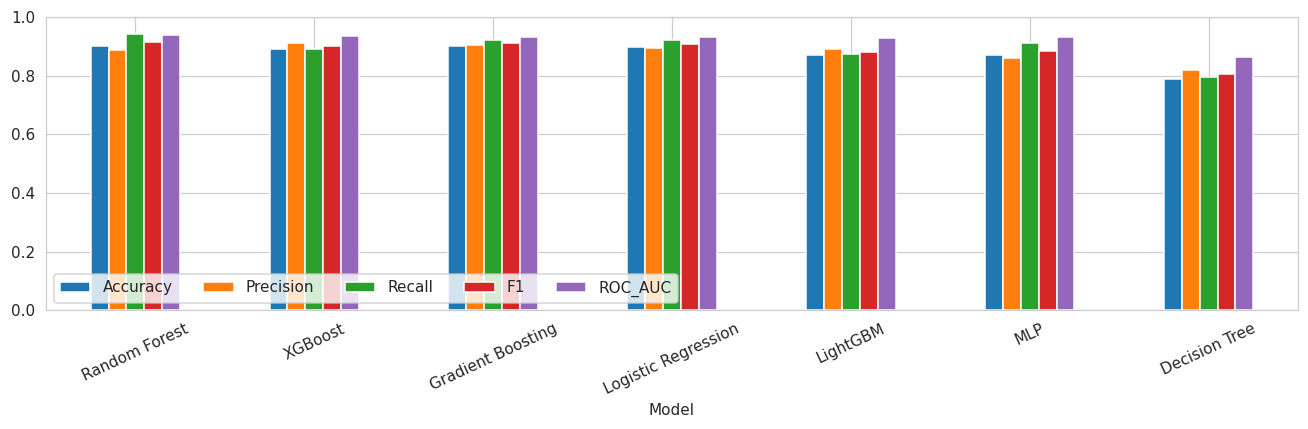

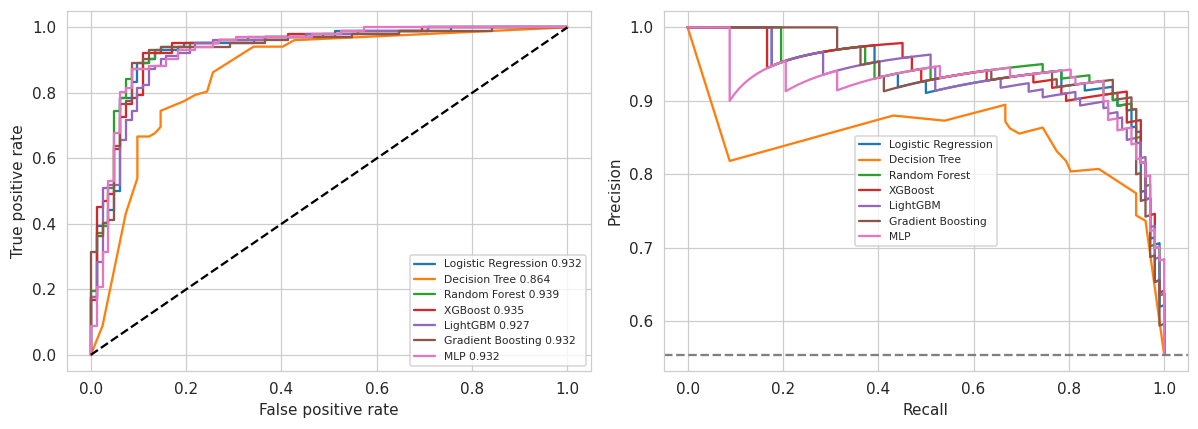

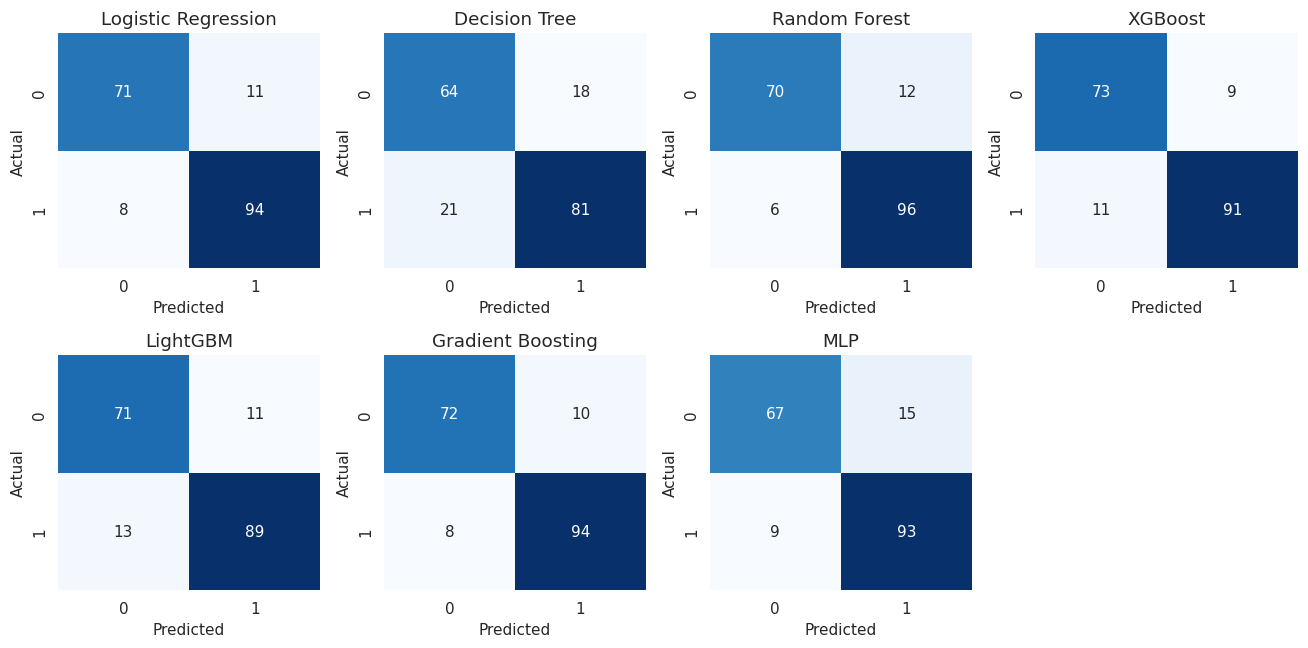

In [7]:
def metrics(y_true,prob,threshold=.5):
    pred=(prob>=threshold).astype(int);tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'Accuracy':accuracy_score(y_true,pred),'Precision':precision_score(y_true,pred,zero_division=0),
            'Recall':recall_score(y_true,pred),'F1':f1_score(y_true,pred),'ROC_AUC':roc_auc_score(y_true,prob),
            'AP':average_precision_score(y_true,prob),'Specificity':tn/(tn+fp),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
probs={};result_rows=[]
for name,pipeline in pipelines.items():
    pipeline.fit(Xtr,ytr);prob=pipeline.predict_proba(Xte)[:,1];probs[name]=prob
    result_rows.append({'Model':name,**metrics(yte,prob)})
results=pd.DataFrame(result_rows).set_index('Model').loc[cv_table.Model].reset_index()
results=results.merge(cv_table,on='Model');display(results.round(4));results.to_csv(OUT/'test_results.csv',index=False)
dummy=DummyClassifier(strategy='prior').fit(Xtr,ytr);baseline=metrics(yte,dummy.predict_proba(Xte)[:,1]);print('다수 클래스 기준선:',baseline)
# 그림 9 성능 비교
metric_cols=['Accuracy','Precision','Recall','F1','ROC_AUC']
results.set_index('Model')[metric_cols].plot.bar(figsize=(12,4),ylim=(0,1),rot=25);plt.legend(loc='lower left',ncol=5);savefig(9)
# 그림 10 ROC와 PR 곡선
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,p in probs.items():
    fpr,tpr,_=roc_curve(yte,p);axs[0].plot(fpr,tpr,label=f'{name} {roc_auc_score(yte,p):.3f}')
    precision,recall,_=precision_recall_curve(yte,p);axs[1].plot(recall,precision,label=name)
axs[0].plot([0,1],[0,1],'k--');axs[0].set(xlabel='False positive rate',ylabel='True positive rate');axs[0].legend(fontsize=7)
axs[1].axhline(yte.mean(),ls='--',color='gray');axs[1].set(xlabel='Recall',ylabel='Precision');axs[1].legend(fontsize=7);savefig(10)
# 그림 11 혼동 행렬
fig,axs=plt.subplots(2,4,figsize=(12,6))
for (name,p),ax in zip(probs.items(),axs.flat):
    sns.heatmap(confusion_matrix(yte,p>=.5),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
    ax.set(title=name,xlabel='Predicted',ylabel='Actual')
axs.flat[-1].axis('off');savefig(11)


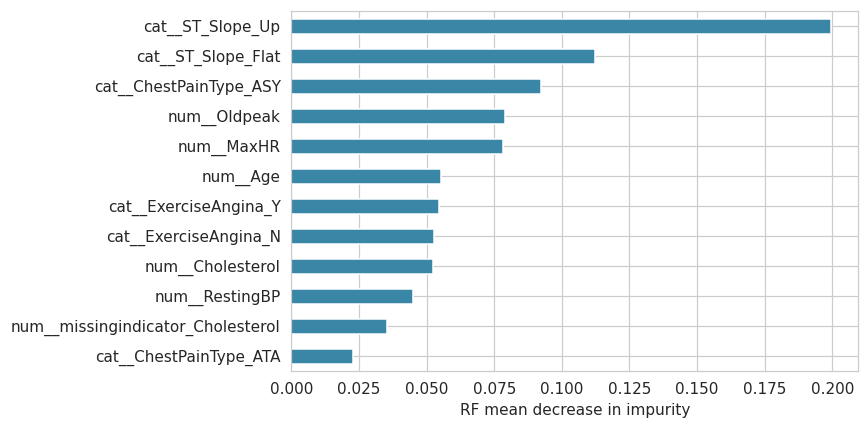

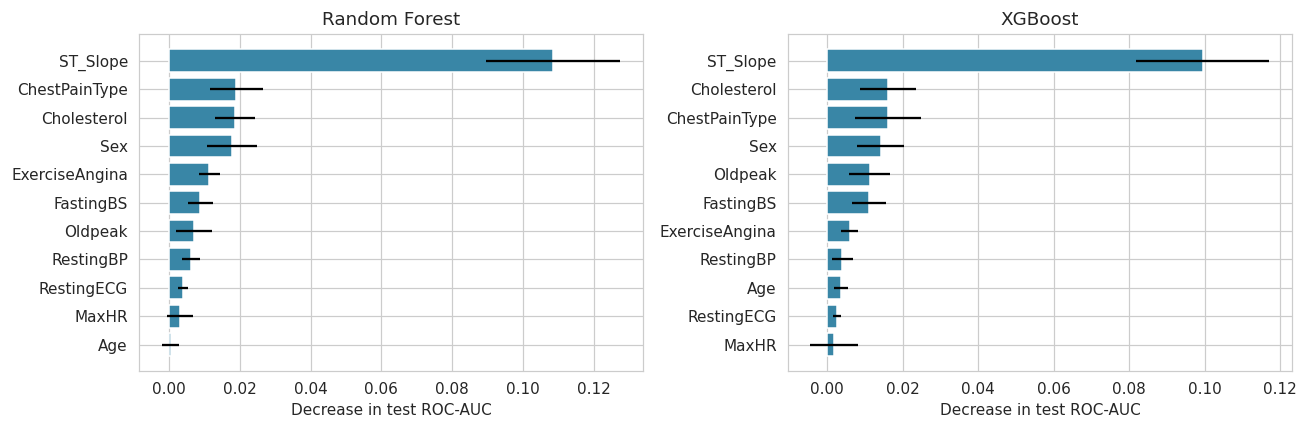

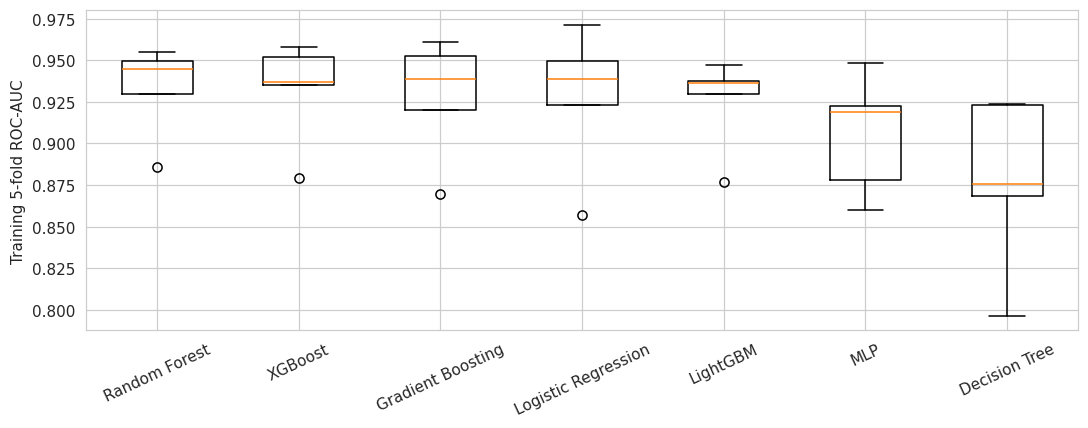

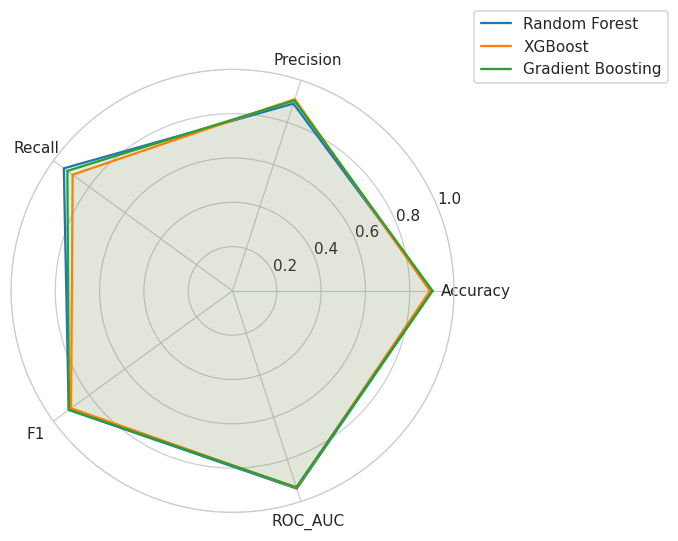

In [8]:
# 그림 12 RF 원핫 특징 MDI / 그림 13 원래 변수 단위 순열 중요도
rf=pipelines['Random Forest'];feature_names=rf.named_steps['preprocess'].get_feature_names_out()
mdi=pd.Series(rf.named_steps['model'].feature_importances_,index=feature_names).sort_values(ascending=False)
mdi.to_csv(OUT/'rf_mdi.csv');mdi.head(12).sort_values().plot.barh(figsize=(8,4),color='#3986A6');plt.xlabel('RF mean decrease in impurity');savefig(12)
# 테스트 순열 중요도는 최종 평가 후의 설명용 분석이며 모델 재선택에 사용하지 않는다.
perm_tables={};fig,axs=plt.subplots(1,2,figsize=(12,4))
for name,ax in zip(['Random Forest','XGBoost'],axs):
    p=permutation_importance(pipelines[name],Xte,yte,scoring='roc_auc',n_repeats=15,random_state=SEED,n_jobs=1)
    tab=pd.DataFrame({'variable':X.columns,'mean':p.importances_mean,'sd':p.importances_std}).sort_values('mean')
    perm_tables[name]=tab;tab.to_csv(OUT/(name.replace(' ','_')+'_permutation.csv'),index=False)
    ax.barh(tab.variable,tab['mean'],xerr=tab.sd,color='#3986A6');ax.set_title(name);ax.set_xlabel('Decrease in test ROC-AUC')
savefig(13)
# 그림 14 훈련 교차검증 분포
plt.figure(figsize=(10,4));plt.boxplot([cv_scores[n] for n in cv_table.Model],tick_labels=list(cv_table.Model));plt.xticks(rotation=25);plt.ylabel('Training 5-fold ROC-AUC');savefig(14)
# 그림 15 교차검증 상위 3개 모델의 테스트 지표
angles=np.linspace(0,2*np.pi,5,endpoint=False).tolist();angles+=angles[:1]
fig,ax=plt.subplots(figsize=(6,5),subplot_kw={'polar':True})
for n in cv_table.Model.head(3):
    vals=results.set_index('Model').loc[n,metric_cols].to_numpy(float).tolist();vals+=vals[:1]
    ax.plot(angles,vals,label=n);ax.fill(angles,vals,alpha=.07)
ax.set_xticks(angles[:-1],metric_cols);ax.set_ylim(0,1);ax.legend(loc='upper right',bbox_to_anchor=(1.5,1.15));savefig(15)


### 5 추가 검증과 민감도 분석
훈련 OOF 예측에서 재현율 0.90 이상인 임계값 중 특이도가 가장 높은 값을 선택한다. 동점이면 가장 높은 임계값을 선택한다. 0.90은 교육용 운영 가정이며 임상 기준이 아니다. 선택 임계값을 테스트에 한 번 적용한다. 테스트 AUC의 95% 구간은 층화 부트스트랩 2,000회로 계산하며 모델 재학습의 변동은 포함하지 않는다.

콜레스테롤 제거 실험과 Age×Oldpeak, MaxHR÷Age 두 파생 변수 추가 실험은 동일한 훈련 폴드에서만 수행한다. 기본 모델을 사후 교체하지 않는다.

In [9]:
best=pipelines[best_name]
oof=cross_val_predict(best,Xtr,ytr,cv=cv,method='predict_proba',n_jobs=1)[:,1]
fpr,tpr,thrs=roc_curve(ytr,oof)
valid=np.where((tpr>=.9)&np.isfinite(thrs))[0]
idx=sorted(valid,key=lambda i:(fpr[i],-thrs[i]))[0];threshold=float(thrs[idx])
threshold_result=metrics(yte,probs[best_name],threshold)
print('OOF 선택 임계값:',threshold,'OOF 재현율:',tpr[idx],'OOF 특이도:',1-fpr[idx]);print('테스트:',threshold_result)
rng=np.random.default_rng(SEED); yy=yte.to_numpy();pp=probs[best_name];a0=np.flatnonzero(yy==0);a1=np.flatnonzero(yy==1)
boots=[]
for _ in range(2000):
    ix=np.r_[rng.choice(a0,len(a0)),rng.choice(a1,len(a1))];boots.append(roc_auc_score(yy[ix],pp[ix]))
auc_ci=np.quantile(boots,[.025,.975]);print('조건부 테스트 AUC 95% CI:',auc_ci)
# 성별 성능은 표본 수와 구간을 함께 확인한다.
subgroups=[]
for sex in ['F','M']:
    ix=(Xte.Sex==sex).to_numpy();ys=yy[ix];pred=pp[ix]>=.5
    pos=int((ys==1).sum());tp=int(((ys==1)&pred).sum());lo,hi=wilson(tp,pos)
    subgroups.append({'Sex':sex,'n':int(ix.sum()),'positive_n':pos,'Recall':tp/pos,'Recall_low':lo,'Recall_high':hi,'AUC':roc_auc_score(ys,pp[ix])})
subgroups=pd.DataFrame(subgroups);display(subgroups);subgroups.to_csv(OUT/'subgroups.csv',index=False)
# 같은 결측 정책을 사용하되 콜레스테롤 및 그 결측 지표를 함께 제외한다.
reduced_num=[c for c in num if c!='Cholesterol']
reduced=Pipeline([('preprocess',preprocess(reduced_num,cat)),('model',LogisticRegression(max_iter=2000,random_state=SEED))])
reduced_scores=cross_val_score(reduced,Xtr,ytr,cv=cv,scoring='roc_auc')
def add_features(frame):
    frame=frame.copy();frame['Age_Oldpeak']=frame.Age*frame.Oldpeak;frame['HR_per_Age']=frame.MaxHR/frame.Age
    return frame
engineered=Pipeline([('feature',FunctionTransformer(add_features,validate=False)),('preprocess',preprocess(num+['Age_Oldpeak','HR_per_Age'],cat)),('model',LogisticRegression(max_iter=2000,random_state=SEED))])
engineered_scores=cross_val_score(engineered,Xtr,ytr,cv=cv,scoring='roc_auc')
ablation=pd.DataFrame({'Baseline_LR':cv_scores['Logistic Regression'],'No_Cholesterol_LR':reduced_scores,'Engineered_LR':engineered_scores})
display(ablation);print('평균:',ablation.mean());ablation.to_csv(OUT/'ablation.csv',index=False)
summary={'source_kaggle':'https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction','download_mirror':'https://raw.githubusercontent.com/benbobyabraham/heart_failure_prediction_dataset_kaggle/main/heart.csv',
         'sha256':sha,'versions':versions,'n':len(df),'class_counts':{str(k):int(v) for k,v in y.value_counts().items()},
         'train_n':len(Xtr),'test_n':len(Xte),'best_model':best_name,'auc_ci':auc_ci.tolist(),
         'threshold':threshold,'oof_recall':float(tpr[idx]),'oof_specificity':float(1-fpr[idx]),
         'threshold_test':threshold_result,'baseline':baseline,'groups':groups,'ablation_means':ablation.mean().to_dict()}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('분석 완료. 결과 폴더:',OUT.resolve())


OOF 선택 임계값: 0.49337832484975347 OOF 재현율: 0.9039408866995073 OOF 특이도: 0.8018292682926829
테스트: {'Accuracy': 0.8967391304347826, 'Precision': 0.8807339449541285, 'Recall': 0.9411764705882353, 'F1': 0.909952606635071, 'ROC_AUC': 0.9386657101865137, 'AP': 0.941936567093043, 'Specificity': np.float64(0.8414634146341463), 'TN': 69, 'FP': 13, 'FN': 6, 'TP': 96}
조건부 테스트 AUC 95% CI: [0.89610234 0.97238164]
평균: Baseline_LR          0.928014
No_Cholesterol_LR    0.922599
Engineered_LR        0.927148
dtype: float64
분석 완료. 결과 폴더: /workspace/scratch/eec686789cbb/output/results


,Sex,n,positive_n,Recall,Recall_low,Recall_high,AUC
0,F,38,6,0.833333,0.436497,0.969947,0.963542
1,M,146,96,0.947917,0.883815,0.977550,0.917500


,Baseline_LR,No_Cholesterol_LR,Engineered_LR
0,0.923452,0.919512,0.921201
1,0.856715,0.861953,0.856528
2,0.949495,0.936401,0.949121
3,0.971568,0.964834,0.971568
4,0.938841,0.930294,0.937322
